# Spikes2Slope — Research checkpoint with Liz
**November 3, 2026 | Allen Visual Coding Neuropixels | Exploratory Q1**

### The research question
**Can extracellular waveform features distinguish optotagging-supported Pvalb, Sst, and Vip interneuron populations better than chance?**

Why this matters to Spikes2Slope: If electrophysiological features carry information about inhibitory subclasses, we may eventually estimate class-specific spiking beyond the small subset of neurons with experimental tagging evidence. That could inform later LFP/aperiodic or model-based analyses. **None of the current work establishes a direct measure of synaptic E/I balance or an LFP-exponent relationship.**

### What this checkpoint covers
1. The recordings and the analyzed population.
2. Where putative interneuron labels come from, and the exact Allen tutorial criteria.
3. Why some labels need caution (one evoked spike is enough to pass).
4. Candidate counts, anatomical coverage, and correspondence to spike-sorted units.
5. Waveform duration/half-width distributions, including the violin plot.
6. Preliminary SVM performance and what “better than chance” still requires.
7. Concrete decisions needed for the next phase.

**Evidence labels:** “Candidate” = unit that passed our light-response and sorting-quality rules. “Unknown” = no assigned candidate label, **not** “excitatory.” A candidate is not automatically a molecularly confirmed neuron.

**Sources:** [Allen optotagging tutorial](https://allensdk.readthedocs.io/en/latest/_static/examples/nb/ecephys_optotagging.html) · [Allen Visual Coding Neuropixels documentation](https://allensdk.readthedocs.io/en/latest/visual_coding_neuropixels.html) · project notebooks `optotagcheck.ipynb`, `kilosortvalidation.ipynb`, `waveform.ipynb`, and `svm.ipynb`.

**Execution:** The main walkthrough reads previously generated CSV files on WD_BLACK. It should not request additional NWB downloads. The notebook is designed to be read and executed cell by cell during the meeting.

## 1. What data are we actually analyzing?

The Allen Visual Coding dataset contains spike-sorted units recorded with Neuropixels probes. A *unit* is a putative neuron identified through spike sorting, not a recording electrode or a cell-type label.

There are **three different populations** in our saved results, which should not be conflated:

- **40,010:** units in our broader Allen quality-filtered master waveform table, which includes additional sessions beyond the optotagging subset. The longer-term idea would be to predict identities for some of those unknown units, assuming we can establish that the classifier is reliable enough and can handle neurons outside the three target classes?
- **8,579:** units **examined** by our optotagging analysis in **28 Pvalb-, Sst-, or Vip-Cre sessions** and our seven chosen regions. This is the pre-selection analysis population; not all 8,579 pass our combined QC.
- **1,127:** units that passed **both** our Allen-tutorial optical response criterion **and** the combined sorting-quality filters (the `matched_candidate` subset). Approximately 13.1% of examined units.

The seven selected regions are **VISp, VISl, VISal, VISam, VISpm, VISrl, and LGd**. Six are visual cortical areas; **LGd is thalamus**, so pooling all seven could create anatomical confounding.

The remaining examined units are **not classified as excitatory**. They are simply not assigned a QC-matched optotagging candidate label by this procedure.

**Question for Liz:** Should Q1 include all seven regions, only visual cortex, or VISp alone? Are we comparing the appropriate anatomical populations?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("/Volumes/WD_BLACK/Spikes2Slope")
RESULTS = ROOT / "opto_results"
opto_path = RESULTS / "all_opto_unit_results.csv"
master_path = RESULTS / "master_waveform_features.csv"

for path in (opto_path, master_path):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing saved output: {path}\n"
            "Mount WD_BLACK or adjust ROOT to the existing cache; "
            "do not re-download raw recordings for this meeting."
        )

opto = pd.read_csv(opto_path)
master = pd.read_csv(master_path)
for col in ["candidate_tagged", "allen_qc", "snr_qc", "matched_candidate"]:
    opto[col] = opto[col].astype(bool)
master["is_opto_candidate"] = master["is_opto_candidate"].astype(bool)

assert opto["unit_id"].is_unique
assert master["unit_id"].is_unique
print(f"Analyzed units: {len(opto):,} in {opto.ecephys_session_id.nunique()} sessions")
print(f"QC-matched optotagging candidates: {opto.matched_candidate.sum():,}")
print(f"Broader Allen quality-filtered units in master table: {len(master):,}")
display(opto[["unit_id", "ecephys_session_id", "cre_line", "region",
              "n_pulses", "baseline_rate_hz", "evoked_rate_hz",
              "response_ratio", "matched_candidate"]].head(4))

Analyzed units: 8,579 in 28 sessions
QC-matched optotagging candidates: 1,127
Broader Allen quality-filtered units in master table: 40,010


,unit_id,ecephys_session_id,cre_line,region,n_pulses,baseline_rate_hz,evoked_rate_hz,response_ratio,matched_candidate
0,950907555,721123822,Pvalb,VISam,45,0.000000,5.555556,5.555556,True
1,950907350,721123822,Pvalb,VISam,45,0.000000,2.777778,2.777778,True
2,950907356,721123822,Pvalb,VISam,45,2.777778,0.000000,0.000000,False
3,950907360,721123822,Pvalb,VISam,45,0.000000,0.000000,0.000000,False


## 2. How did we assign putative Pvalb / Sst / Vip labels?

**Allen provides the experimental Cre line for each recording session; it does not provide definitive PV/SST/VIP molecular identities for every sorted unit.**

- In a **Pvalb-Cre session**, the optogenetic manipulation targets a Pvalb-related population.
- In an **Sst-Cre session**, it targets an Sst-related population.
- In a **Vip-Cre session**, it targets a Vip-related population.

Our program then asks **which individual sorted units increase firing during optical stimulation**. Only those passing the optical-response rule *and* quality controls receive the **putative class label associated with that session's Cre line**. Other units remain unlabeled.

### Original optotagging detector (following Allen's tutorial)
- Select epochs where `stimulus_name == "pulse"` and duration is between 9 and 20 ms, corresponding to nominal 10-ms pulses.
- **Baseline:** −10 to −2 ms before light onset (8 ms).
- **Evoked:** +1 to +9 ms after light onset (8 ms).
- For each unit, compute average spikes per window and convert to Hz.
- Mark an **optotagging response candidate** if:

$$
\text{Response ratio} =
\frac{\text{Evoked firing rate}}{\text{Baseline firing rate} + 1}
> 2
$$

The added 1 Hz stabilizes the denominator when baseline firing is zero; the score is **not** a simple fold change.

### Sorting-quality criteria
Allen provides these unit-quality metrics and documented example/default thresholds:
- **Presence ratio ≥ 0.95:** unit detected across most of the recording.
- **ISI violations ≤ 0.5:** controls for possible spike-train contamination.
- **Amplitude cutoff ≤ 0.1:** limits estimated missed spikes.
- **SNR ≥ 1:** **our additional choice**, using an Allen-provided metric; not a molecular-identification threshold.

`matched_candidate = candidate_tagged & snr_qc`, where `snr_qc` combines the four quality conditions above.

**Question for Liz:** Is this Allen-tutorial-derived definition sufficient for **exploratory Q1 labels**, or should we define a more stringent optotagging reliability standard before training or interpreting the classifier? Is the extra SNR ≥ 1 filter appropriate?

In [2]:
qc_checks = pd.DataFrame([
    ["Allen-style response threshold", int(opto["candidate_tagged"].sum())],
    ["Pass Allen quality metrics", int(opto["allen_qc"].sum())],
    ["Pass Allen QC + SNR >= 1", int(opto["snr_qc"].sum())],
    ["Response threshold AND combined QC", int(opto["matched_candidate"].sum())],
], columns=["Criterion", "Number of analyzed units"])
display(qc_checks)

# Verify the detector against values saved by optotagcheck.ipynb.
calculated_ratio = opto["evoked_rate_hz"] / (opto["baseline_rate_hz"] + 1)
assert np.allclose(opto["response_ratio"], calculated_ratio)
assert (opto["candidate_tagged"] == (calculated_ratio > 2)).all()
assert (opto["matched_candidate"] ==
        (opto["candidate_tagged"] & opto["snr_qc"])).all()
print("Stored labels match the original detector and QC logic.")

,Criterion,Number of analyzed units
0,Allen-style response threshold,1152
1,Pass Allen quality metrics,8579
2,Pass Allen QC + SNR >= 1,8415
3,Response threshold AND combined QC,1127


Stored labels match the original detector and QC logic.


## 3. A limitation discovered: the detector can accept one evoked spike

An individual unit can satisfy the original response-ratio rule even if its evidence of light-driven firing is sparse.

**Concrete example:** With **45 optical pulses** and an **8-ms evoked window**, total response-window exposure is `45 × 0.008 = 0.36 s`. **One** evoked spike gives an estimated evoked firing rate of **2.78 Hz**. If the baseline windows contain **zero** spikes, the score is `2.78 / (0 + 1) = 2.78 > 2`, so the unit passes the optical-response rule.

Our audit found **261 of 1,127 candidates (23.2%)** with exactly **one** evoked-window spike and **zero** observed baseline-window spikes. The percentage differs by Cre line.

**Interpretation:** This shows that the tutorial criterion is a *candidate detector*, not a demonstration of repeatable pulse-locked activation for every selected unit. These 261 are **not proven false positives**. Zero observed baseline spikes does not establish a true baseline rate of zero.

A later exploratory comparison of pooled evoked and baseline counts, with BH correction across **all 8,579 examined units**, flagged **213/1,127** candidates. That screen is **not definitive ground truth**, and its low-count power, independence, timing, and artifact assumptions must be considered. We should not silently replace the original 1,127 labels with 213 labels.

**Question for Liz:** Keep all tutorial candidates as a documented exploratory baseline, or prioritize further response reliability checks and a separate higher-confidence sensitivity analysis?

In [3]:
candidates = opto.loc[opto["matched_candidate"]].copy()
WINDOW_S = 0.008
for prefix in ("evoked", "baseline"):
    estimated = (candidates[f"{prefix}_rate_hz"]
                 * candidates["n_pulses"] * WINDOW_S)
    assert np.allclose(estimated, np.rint(estimated), atol=1e-6), (
        f"{prefix} count reconstruction failed; inspect rate definition"
    )
    candidates[f"{prefix}_spikes"] = np.rint(estimated).astype(int)

candidates["one_spike_zero_baseline"] = (
    (candidates["evoked_spikes"] == 1)
    & (candidates["baseline_spikes"] == 0)
)
candidates["two_or_fewer_evoked"] = candidates["evoked_spikes"] <= 2

reliability_summary = candidates.groupby("cre_line").agg(
    candidates=("unit_id", "size"),
    one_spike_zero_baseline=("one_spike_zero_baseline", "sum"),
    two_or_fewer_evoked=("two_or_fewer_evoked", "sum"),
    median_evoked_spikes=("evoked_spikes", "median")
)
reliability_summary["pct_two_or_fewer"] = (
    100 * reliability_summary["two_or_fewer_evoked"]
    / reliability_summary["candidates"]
)
display(reliability_summary.round(1))
print("Total one-spike/zero-baseline:",
      int(candidates["one_spike_zero_baseline"].sum()),
      "/", len(candidates))

,candidates,one_spike_zero_baseline,two_or_fewer_evoked,median_evoked_spikes,pct_two_or_fewer
cre_line,,,,,
Pvalb,345,56,91,9.0,26.4
Sst,535,145,228,3.0,42.6
Vip,247,60,106,3.0,42.9


Total one-spike/zero-baseline: 261 / 1127


## 4. What labeled sample did we obtain?

The **1,127** QC-matched candidates come from three genotype-targeted session groups:

- **Pvalb:** 345 candidates across 8 sessions.
- **Sst:** 535 candidates across 12 sessions.
- **Vip:** 247 candidates across 8 sessions.

These are counts of *selected sorted units*, **not** measurements of the true proportion of inhibitory neuron subclasses in the tissue. Optical detection is incomplete and depends on experimental conditions, anatomy, and the selection rule.

Each session has **one Cre label**, so genotype is perfectly nested within session. This creates an important challenge for interpreting any classification model: recorded waveform differences could reflect session-specific or anatomical differences as well as cell-type-related information.

**Question for Liz:** Is a three-class Pvalb/Sst/Vip candidate classifier the intended Q1 endpoint? Do we need region and layer restrictions before evaluating class differences?

,n_candidates,n_sessions
cre_line,,
Pvalb,345,8
Sst,535,12
Vip,247,8


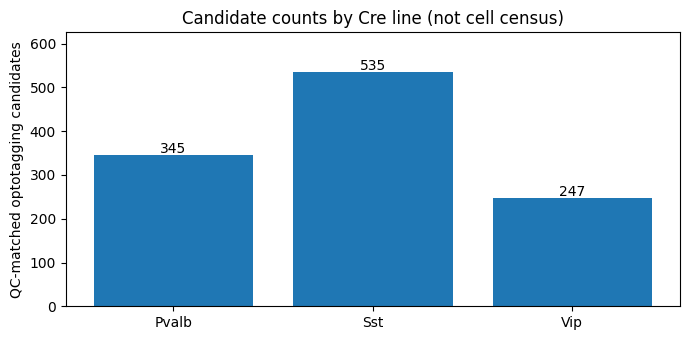

In [4]:
counts = (candidates.groupby("cre_line")
          .agg(n_candidates=("unit_id", "nunique"),
               n_sessions=("ecephys_session_id", "nunique"))
          .reindex(["Pvalb", "Sst", "Vip"]))
display(counts)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(counts.index, counts["n_candidates"])
ax.set(ylabel="QC-matched optotagging candidates",
       title="Candidate counts by Cre line (not cell census)")
for i, val in enumerate(counts["n_candidates"]):
    ax.text(i, val + 6, str(val), ha="center")
ax.set_ylim(0, counts["n_candidates"].max() * 1.17)
plt.tight_layout()
plt.show()

## 5. Kilosort–optotagging correspondence

Allen used **Kilosort2 to separate extracellular spikes into putative units**. Kilosort provides spike sorting—not molecular Pvalb, Sst, or Vip labels.

Our correspondence validation checks that the optotagging results map to the same Allen **unit IDs**, **session IDs**, **regions**, and available **unit-quality metrics** used in the waveform feature table.

This is necessary because a mislabeled join would make the classifier learn from the wrong neuron. **It is not a validation against an independent molecular classifier.**

The broader waveform feature table labels other units `unknown` when they do not meet our candidate criterion. `unknown` does not imply excitatory identity.

**Question for Liz:** Does this unit-level correspondence address what you meant by “validate Kilosort,” or were you intending a separate fast-/regular-spiking waveform comparison? Kilosort2 does not output independent PV/SST/VIP labels.

**Related outstanding check:** Liz's notes also mention recomputing waveform duration and half-width directly from mean peak-channel waveforms for approximately **20 units** to validate Allen-derived features. Our preliminary polarity check covered only 30 sampled units and does not replace that verification.

In [5]:
check = candidates[["unit_id", "ecephys_session_id", "region"]].merge(
    master[["unit_id", "ecephys_session_id",
            "ecephys_structure_acronym", "cell_type_label"]],
    on="unit_id", how="left", validate="one_to_one",
    suffixes=("_opto", "_waveform"), indicator=True
)
audit = pd.Series({
    "Missing candidate unit IDs in master": int((check["_merge"] != "both").sum()),
    "Session mismatches": int((check["ecephys_session_id_opto"]
                               != check["ecephys_session_id_waveform"]).sum()),
    "Region mismatches": int((check["region"]
                              != check["ecephys_structure_acronym"]).sum())
})
# Cre-line identity comes from the experimental session metadata, not Kilosort.
display(audit.rename("Count").to_frame())
print("All remaining master rows labeled 'unknown' are unlabeled, not excitatory.")

,Count
Missing candidate unit IDs in master,0
Session mismatches,0
Region mismatches,0


All remaining master rows labeled 'unknown' are unlabeled, not excitatory.


## 6. Do extracellular waveform properties differ between candidate classes?

**Waveform duration** typically measures the interval from the negative trough to the following positive peak of a unit's extracellular action potential. **Half-width** measures waveform width at a half-amplitude criterion. These are temporal measurements, usually reported in milliseconds.

A longstanding population-level observation is that many Pvalb-associated, fast-spiking interneurons have relatively **narrow extracellular waveforms**. But extracellular spike width is **not a definitive marker of molecular cell identity**; other classes can overlap, and waveform properties can vary with recording location, layer, and spike-sorting conditions.

We extracted Allen-provided waveform metrics for our 1,127 candidate units. The following visualizations use those **computed features**, not the full raw voltage traces.

**Question for Liz:** Before extending the classifier, should we validate selected waveform metrics directly from the peak-channel mean waveforms and assess region/layer effects?

waveform_duration        waveform_halfwidth       
                            count median              count median
cell_type_label                                                   
Pvalb                         345  0.426                342  0.179
Sst                           535  0.604                529  0.206
Vip                           247  0.632                240  0.192

/var/folders/xw/_wbvd7ps4xv0mqqnxnwfzcb00000gn/T/ipykernel_28827/1815852770.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(arrays, labels=labels, showfliers=False)
/var/folders/xw/_wbvd7ps4xv0mqqnxnwfzcb00000gn/T/ipykernel_28827/1815852770.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(arrays, labels=labels, showfliers=False)


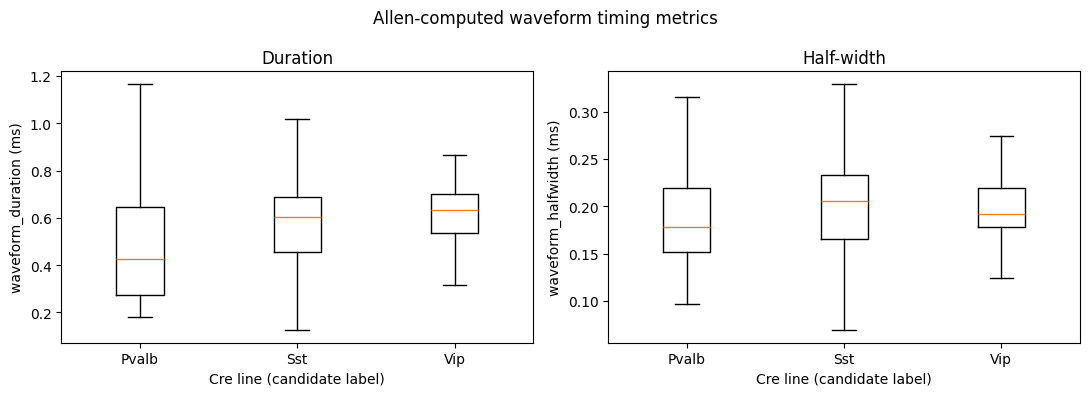

In [6]:
labels = ["Pvalb", "Sst", "Vip"]
tagged = master.loc[
    master["is_opto_candidate"]
    & master["cell_type_label"].isin(labels)
].copy()

features = ["waveform_duration", "waveform_halfwidth",
            "waveform_PT_ratio", "waveform_repolarization_slope",
            "waveform_recovery_slope", "waveform_amplitude",
            "waveform_spread"]
assert all(col in tagged.columns for col in features)
assert len(tagged) == int(opto["matched_candidate"].sum()), "Candidate joins need investigation"
display(
    tagged.groupby("cell_type_label")[["waveform_duration", "waveform_halfwidth"]]
    .agg(["count", "median"]).reindex(labels).round(3)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature, title in zip(
    axes,
    ["waveform_duration", "waveform_halfwidth"],
    ["Duration", "Half-width"]
):
    arrays = [tagged.loc[tagged.cell_type_label == label, feature]
              .dropna().to_numpy() for label in labels]
    ax.boxplot(arrays, labels=labels, showfliers=False)
    ax.set(title=title, xlabel="Cre line (candidate label)",
           ylabel=f"{feature} (ms)")
fig.suptitle("Allen-computed waveform timing metrics")
plt.tight_layout()
plt.show()

### 6a. Waveform duration: full candidate distributions

A **violin plot** shows the smoothed distribution of waveform duration within each candidate group. **Wider** sections indicate that more units have durations around that value; horizontal lines indicate quartiles (25%, median, and 75%).

**Interpretation from our preliminary figure:**
- **Pvalb** includes a prominent **short-duration** population and an additional broader-duration population, suggesting heterogeneous recorded waveform shapes.
- **Sst and Vip** have substantially overlapping duration distributions, especially around their central values.
- The overlap suggests that **waveform duration alone is unlikely to separate all three classes reliably**. This motivates comparing multiple waveform features, rather than assigning a deterministic cell-type label from spike width.

The apparent **bimodality** in Pvalb is an observation that needs caution: it could reflect true heterogeneity, anatomy, experimental/session variation, or candidate-label uncertainty. We have not yet tested those explanations.

**Question for Liz:** Is this the expected pattern, and should we investigate the Pvalb bimodality by region, layer, or reliability before interpreting our SVM?

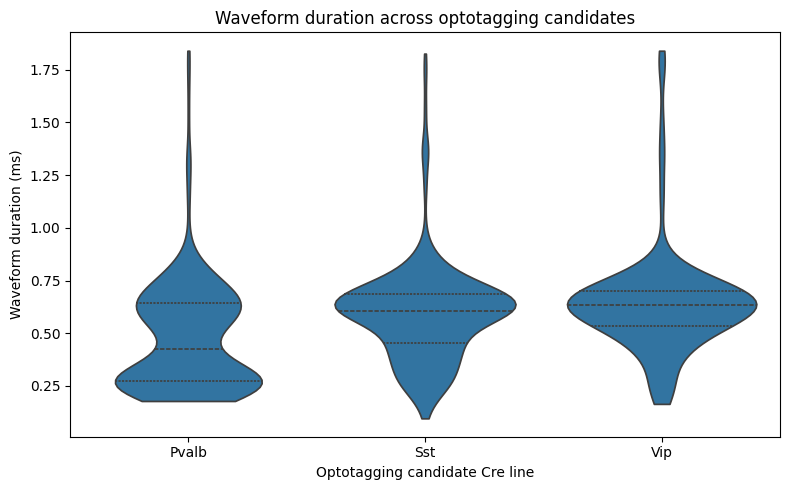

In [7]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(
    data=tagged,
    x="cell_type_label",
    y="waveform_duration",
    order=labels,
    inner="quartile",
    cut=0,
    ax=ax
)
ax.set(
    xlabel="Optotagging candidate Cre line",
    ylabel="Waveform duration (ms)",
    title="Waveform duration across optotagging candidates"
)
plt.tight_layout()
plt.show()

### 6b. The two-feature view: duration versus half-width

A scatterplot makes it easier to see whether two conventional waveform timing features form separate candidate-class groups or overlap. This is **descriptive**, not a statistical classification test.

A fixed random sample is used here **only to reduce overplotting**; all candidate units are used in the SVM.

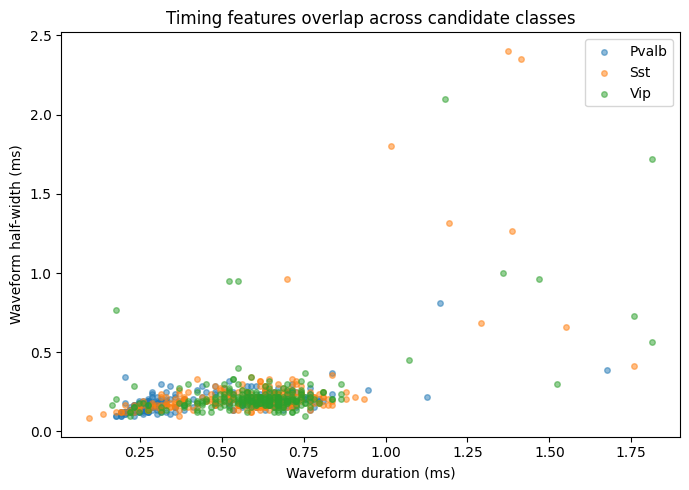

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for label in labels:
    subset = tagged.loc[
        tagged["cell_type_label"] == label,
        ["waveform_duration", "waveform_halfwidth"]
    ].dropna()
    subset = subset.sample(n=min(250, len(subset)), random_state=42)
    ax.scatter(subset["waveform_duration"], subset["waveform_halfwidth"],
               label=label, s=16, alpha=0.5)
ax.set(xlabel="Waveform duration (ms)",
       ylabel="Waveform half-width (ms)",
       title="Timing features overlap across candidate classes")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Preliminary SVM: can waveform features predict our putative labels?

We trained preliminary supervised classifiers on the **1,127 candidate units**, using their **Cre-line-derived candidate labels** as the target. No optical-response ratio or timing features were used as model inputs.

**Inputs:** seven Allen-computed waveform features: duration, half-width, peak-to-trough ratio, repolarization slope, recovery slope, amplitude, and spread. We also tested adding firing rate.

**Models:** a linear SVM, an RBF (nonlinear) SVM, and an RBF SVM with firing rate. Missing values are imputed and features standardized **within each training fold**, avoiding straightforward preprocessing leakage.

**Validation:** five folds built by stratifying **sessions** by Cre line, then withholding entire sessions (not random individual units). This reduces same-session leakage, but the model may still learn recording, anatomical, mouse, or hardware correlates of a Cre-line-specific session. **Independent unit counts do not imply independent animal replication.**

**Metrics:**
- **Balanced accuracy** averages recall across Pvalb, Sst, and Vip, reducing sensitivity to different sample sizes.
- **Macro-F1** averages per-class classification performance.
- A nominal balanced-accuracy reference for three classes is **1/3 = 33.3%**, but we **have not run a valid session-aware permutation/null analysis**, so we cannot claim statistical significance.

Earlier exploratory values were **0.400** (linear/waveform), **0.444** (RBF/waveform), and **0.452** (RBF/waveform+firing rate). The following code reruns the original models to reproduce the numbers.

**Questions for Liz:** Does this train/test design answer Q1 appropriately? Should the immediate next step be permutation testing, waveform validation, restricting anatomy, or a different modeling approach?

In [9]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.base import clone
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay
)

model_data = tagged.reset_index(drop=True)
X = model_data[features]
y = model_data["cell_type_label"]
groups = model_data["ecephys_session_id"]

session_labels = model_data.groupby("ecephys_session_id")["cell_type_label"].first()
assert (model_data.groupby("ecephys_session_id")["cell_type_label"]
        .nunique() == 1).all()

session_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = []
for train_s, test_s in session_cv.split(
    session_labels.index, session_labels.values
):
    train_sessions = session_labels.index[train_s]
    test_sessions = session_labels.index[test_s]
    train_idx = np.flatnonzero(groups.isin(train_sessions))
    test_idx = np.flatnonzero(groups.isin(test_sessions))
    assert set(groups.iloc[train_idx]).isdisjoint(
        set(groups.iloc[test_idx])
    )
    folds.append((train_idx, test_idx))

print(f"{len(model_data):,} candidates; {groups.nunique()} sessions; "
      f"{len(folds)} session-held-out folds")
display(pd.DataFrame({
    "Cre line": labels,
    "Units": [int((y == label).sum()) for label in labels],
    "Sessions": [int((session_labels == label).sum()) for label in labels]
}))

1,127 candidates; 28 sessions; 5 session-held-out folds


,Cre line,Units,Sessions
0,Pvalb,345,8
1,Sst,535,12
2,Vip,247,8


### 7a. Comparing the models

All three models are rerun on the **same candidate population and session-held-out folds**. The goal is to establish a transparent **preliminary baseline**, not select a final architecture.

Pvalb neurons are commonly associated with fast-spiking behavior and can sustain high firing rates so chose to add firing rates to third model

Better mean balanced accuracy than the nominal 33.3% reference is **not yet proof** of above-chance generalization. Model settings are exploratory and have not been optimized using nested cross-validation.

In [10]:
models = {
    "Linear — waveform": (
        make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            LinearSVC(class_weight="balanced", random_state=42, max_iter=10000)
        ), features
    ),
    "RBF — waveform": (
        make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            SVC(kernel="rbf", C=1.0, gamma="scale",
                class_weight="balanced")
        ), features
    ),
    "RBF — waveform + firing rate": (
        make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            SVC(kernel="rbf", C=1.0, gamma="scale",
                class_weight="balanced")
        ), features + ["firing_rate"]
    )
}

model_summaries = []
predictions = {}
for name, (estimator, columns) in models.items():
    fold_scores = []
    oof = np.empty(len(model_data), dtype=object)
    for fold_i, (train_idx, test_idx) in enumerate(folds, start=1):
        fitted = clone(estimator)
        fitted.fit(model_data.iloc[train_idx][columns], y.iloc[train_idx])
        pred = fitted.predict(model_data.iloc[test_idx][columns])
        oof[test_idx] = pred
        fold_scores.append({
            "fold": fold_i,
            "balanced_accuracy": balanced_accuracy_score(
                y.iloc[test_idx], pred
            ),
            "macro_f1": f1_score(
                y.iloc[test_idx], pred, average="macro", labels=labels
            )
        })
    score_df = pd.DataFrame(fold_scores)
    predictions[name] = oof
    model_summaries.append({
        "model": name,
        "mean_balanced_accuracy": score_df["balanced_accuracy"].mean(),
        "mean_macro_f1": score_df["macro_f1"].mean()
    })
model_summary = pd.DataFrame(model_summaries)
display(model_summary.round(3))
print("Nominal 3-class balanced-accuracy reference: 0.333; "
      "NO permutation test performed here.")

,model,mean_balanced_accuracy,mean_macro_f1
0,Linear — waveform,0.400,0.373
1,RBF — waveform,0.444,0.411
2,RBF — waveform + firing rate,0.452,0.422


Nominal 3-class balanced-accuracy reference: 0.333; NO permutation test performed here.


### 7b. Where does the classifier make mistakes?

The confusion matrix below uses held-out-session predictions and is **row normalized**: each row shows how often units assigned to one candidate class were predicted as each class.

The key issue is not just the overall score. It is whether the model distinguishes **all three populations**, or mostly captures the more familiar narrow-Pvalb versus broad-other waveform pattern.

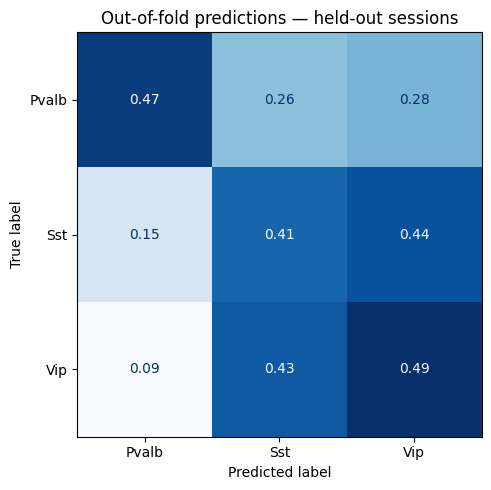

,class,recall
0,Pvalb,0.470
1,Sst,0.407
2,Vip,0.490


In [11]:
best_name = "RBF — waveform + firing rate"
cm = confusion_matrix(
    y, predictions[best_name], labels=labels, normalize="true"
)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False
)
ax.set_title("Out-of-fold predictions — held-out sessions")
plt.tight_layout()
plt.show()
display(pd.DataFrame(
    {"class": labels, "recall": np.diag(cm)}
).round(3))

## 8. Methodological context from our optotagging audit

After the initial SVM, we audited how strongly the selected neurons responded to light.

Two findings matter for interpreting the classifier:

1. **Low-count selection:** About **23.2%** of candidates were supported by **one evoked spike and no observed baseline spikes**. These pass the tutorial detector but have limited evidence of repeatable light activation.
2. **Recording-period differences:** Allen's optotagging documentation reports an earlier **LED** period and a later **laser** period. Candidate response counts were generally higher in later laser-period sessions across Cre lines, but **candidate yield did not change in the same direction for all classes**. This is an observational association, not proof of a causal hardware effect.

We also examined actual pulse-aligned spike rasters for a few units. Some had extremely sparse responses; one Pvalb candidate showed substantial activity across multiple pulses and higher response probability at stronger, temporally interleaved stimulation levels. **These examples do not establish population-wide cell-type accuracy.**

An exploratory FDR-corrected count screen identified **130 Pvalb, 70 Sst, and 13 Vip** candidates with additional statistical evidence (213 total). That is **not** a validated substitute for the original labels, especially given differences in power for low-rate units.

**Question for Liz:** Should label reliability be a prerequisite for interpreting Q1, or a planned robustness/sensitivity analysis after establishing the exploratory classifier and its null performance?

In [12]:
period = opto.copy()
period["hardware_period"] = np.where(
    period["ecephys_session_id"] >= 789848216, "Laser period", "LED period"
)
period["evoked_spikes"] = np.rint(
    period["evoked_rate_hz"] * period["n_pulses"] * WINDOW_S
).astype(int)

period_candidate = period.loc[period["matched_candidate"]].copy()
period_candidate["few_spikes"] = period_candidate["evoked_spikes"] <= 2
session_audit = (period_candidate.groupby(
    ["cre_line", "hardware_period", "ecephys_session_id"]
).agg(
    n_candidates=("unit_id", "size"),
    median_evoked=("evoked_spikes", "median"),
    fraction_few=("few_spikes", "mean")
).reset_index())
display(session_audit.groupby(["cre_line", "hardware_period"]).agg(
    sessions=("ecephys_session_id", "nunique"),
    candidates=("n_candidates", "sum"),
    median_session_evoked=("median_evoked", "median"),
    median_session_fraction_few=("fraction_few", "median")
).round(3))

sessions  candidates  median_session_evoked  \
cre_line hardware_period                                                
Pvalb    LED period              4         137                    2.5   
         Laser period            4         208                   26.0   
Sst      LED period              8         406                    2.5   
         Laser period            4         129                   15.0   
Vip      LED period              3         151                    2.0   
         Laser period            5          96                    5.0   

                          median_session_fraction_few  
cre_line hardware_period                               
Pvalb    LED period                             0.481  
         Laser period                           0.101  
Sst      LED period                             0.515  
         Laser period                           0.175  
Vip      LED period                             0.517  
         Laser period                           0.238

## 9. Where we are and what should come next

### Completed exploratory work
- Identified **28** optotagging sessions containing Pvalb-, Sst-, and Vip-Cre animals.
- Examined **8,579** units in our seven selected regions.
- Used Allen's tutorial-derived response criterion and combined QC to select **1,127** candidate units.
- Verified correspondence between optotagging unit IDs and Allen's sorted-unit metadata; Kilosort supplies **no independent molecular PV/SST/VIP labels**.
- Assembled a **40,010-unit** broader master waveform feature table; labeled optotagging candidates and left other units as **unknown**.
- Visualized waveform timing features and overlap across the three candidate groups.
- Trained three exploratory SVM baselines using session-held-out validation; best earlier mean balanced accuracy about **0.45**.
- Audited candidate response-count limitations and hardware-period differences.

### Not yet established
- A definitive ground-truth label standard for every candidate.
- Independently confirmed molecular identities for all selected units.
- A statistically significant above-chance classifier under an appropriate grouped null.
- Reliable generalization across anatomy, recording hardware, and independent animals.
- Whether alternative models (PhysMAP), waveform remeasurement, or cortical layer information improve predictions.
- Any empirical relationship between these cell types and LFP aperiodic slope.

### Decisions to make with Liz
1. **Reference-label definition:** Are the 1,127 tutorial+QC candidates an acceptable exploratory reference? If not, what evidence is required?
2. **Anatomical scope:** Six visual cortical areas + LGd, visual cortex only, or VISp only?
3. **Kilosort task:** Is unit-ID matching the intended comparison, or should we explicitly analyze fast-/regular-spiking categories?
4. **Feature validity:** Recompute waveform duration and half-width on ~20 raw mean waveforms and extend polarity checks?
5. **Statistical endpoint:** Which grouped permutation/null test and generalization standard will answer “better than chance”?
6. **Future extensions:** When, if at all, to use PhysMAP, K-means, cortical layers, spike-train statistics, or bycycle? (Bycycle is primarily designed for oscillatory cycles, not standard spike-waveform feature extraction.)

**Long-term research connection:** A credible cell-type identification approach may later support analyses of class-specific spiking and the LFP aperiodic component. Waveform identity predictions or population rate ratios would not, by themselves, directly measure synaptic excitation/inhibition balance.